# Aiyagari Model

(If GitHub truncates the output, you can view the full notebook on
[nbviewer](https://nbviewer.org/github/Kanato-Nakakuni/ComputationalMacro/blob/main/Lecture%20notes/Lec08_Aiyagari.ipynb).)

This lecture note is primarily based on *The Aiyagari Model* from the
[Quantitative Economics with Julia](https://julia.quantecon.org/multi_agent_models/aiyagari.html)
website by Jesse Perla, Thomas J. Sargent, and John Stachurski. All errors herein are mine.

## Overview: Key ideas and ingredients

- (*Ex-ante* identical) Households face idiosyncratic ($\neq$ aggregate) risks $\Rightarrow$ Want to insure against the risk  

- Market is incomplete (state-contingent securities are unavailable) $\Rightarrow$ Save to hedge against the risk (*precautionary savings*)  

- Still cannot perfectly hedge against the risks due to *borrowing constraint*  

- Households thus face *uninsurable risks* and are heterogeneous *ex-post*  

### Examples of application:  

- Income and wealth inequality  

- Optimal taxation or debt  

- etc.  

---

### New computational issues

- **Discretizing stochastic income:** Income is often modeled as a continuous-state stochastic process. How can we approximate it (in a discretized manner)?

- **Computing the stationary distribution:** The distributions of income and assets are new equilibrium objects. How can we compute them?

---

### Households

- A unit mass of *ex ante* identical, infinitely lived households  

- Face idiosyncratic income shocks with a common borrowing constraint  

- The savings problem faced by the household is

$$
\max \mathbb E \sum_{t=0}^{\infty} \beta^t u(c_t)
$$

subject to

$$
a_{t+1} + c_t \leq w z_t + (1 + r) a_t
\quad
c_t > 0,
\quad \text{and} \quad
a_t \geq -B
$$

where

- $ c_t $ is current consumption  
- $ a_t $ is assets  
- $ z_t $ is an exogenous component of labor, following an AR(1) process  
- $ w $ is a wage rate  
- $ r $ is a net interest rate  
- $ B $ is the maximum amount that the agent is allowed to borrow  

<br>

- The exogenous process $ z_t \in \mathcal{Z} $ follows a finite state Markov chain with given stochastic matrix $ P_{z_{t+1},z_t} $.  

- The wage and interest rate are fixed over time (stationary equilibrium).  

- Households supply labor inelastically.

<a id='bellman'></a>
The value function reads as:  

$$
V(a,z) = \max_{a'\in[-B,D)} \left\{u(wz + (1+r)a - a') + \mathbb{E}[V(a',z')|z]\right\}~~~:D=wz + (1+r)a \tag{1}
$$

where

$$
\ln(z') = \rho \ln(z) + \varepsilon, \ \varepsilon \sim N(0,\sigma^2)
$$

and

$$
\mathbb{E}[V(a',z')|z] = \sum_{z'\in \mathcal{Z}} P_{z'z} V(a',z') 
$$

---


## Firms

- Firms produce output by hiring capital and labor.  

- Firms act competitively and face constant returns to scale.  

- The firm’s output is  

$$
Y = A K^{\alpha} N^{1 - \alpha}
$$

where  

- $ A $ and $ \alpha $ are parameters with $ A > 0 $ and $ \alpha \in (0, 1) $  
- $ K $ is aggregate capital  
- $ N $ is total labor supply (which is constant in this simple version of the model)  


The firm’s problem is  

$$
\max_{K, N} \left\{ A K^{\alpha} N^{1 - \alpha} - (r + \delta) K - w N \right\}
$$

- The parameter $ \delta $ is the depreciation rate.  

- From the first-order condition with respect to capital, the firm’s inverse demand for capital is  


<a id='equation-aiy-rgk'></a>
$$
r = A \alpha  \left( \frac{K}{N} \right)^{\alpha-1} - \delta 
$$

Using this expression and the firm’s first-order condition for labor, we can pin down
the equilibrium wage rate as a function of $ r $ as  

<a id='equation-aiy-wgr'></a>
$$
w(r) = A  (1 - \alpha)  (A \alpha / (r + \delta))^{\alpha / (1 - \alpha)} 
$$

---

### Equilibrium
**Definition (A Stationary Competitive Equilibrium)**  

A stationary competitive equilibrium consists of a policy function $a' = g(a,z)$, value function $V$, distribution $m(a,z)$, aggregate capital $K$, and prices $r, w$ such that:

- Given $w$ and $r$, $v$ solves the Bellman equation [(1)](#Bellman), and $a' = g(a,z)$ is the associated policy function.  

- Prices are determined competitively:  
  $r = F_K(K,N) - \delta$, &nbsp; $w = F_N(K,N)$.  

- The distribution $m(a,z)$ is stationary and associated with the policy function $g(a,z)$ and the invariant distribution of $z$, $\chi(z)$.  

- Markets clear:  
  - $K = \int_a \int_z g(a,z) \, m(a,z) \, da \, dz$  
  - $N = \int_a \int_z z \cdot m(a,z) \, da \, dz$  

---


### Discretizing AR(1) income process

To solve the household problem and equilibrium, we need to know:
- Transition matrix $P$:  
    - $ij$-th element $P_{ij}$ represents the probability of being in state $j$ tomorrow conditional on being in state $i$ today. 
    - Approximates the AR(1) process characterized by parameters $(\rho,\sigma)$  
    - $\rho$ and $\sigma$ govern the persistence and volatility of the process  

- Invariant distribution of $z$, $\chi(z)$.

The well-known method is Tauchen (1986)'s method.

---


### Tauchen's Method: A Sketch

1. **Generate a state space**: Goal is to get a discretized income space $\mathcal{Z} = \{ z_1, \dots, z_n \}$ that approximates the AR(1) process.
   
   - Choose the number of grid points $n$.  
   - Consider a discretized log-$z$ space, $\log\mathcal{Z} = \{ \log(z_1), \dots, \log(z_n) \}$.
   - Set $\log(z_{1})$ and $\log(z_{n})$ as  

     $$
     \log(z_1) = \log(z_{\min}) = E[\log(z)] - \omega \sigma_{\log z},
     $$
     $$
     \log(z_n) = \log(z_{\max}) = E[\log(z)] + \omega \sigma_{\log z}
     $$  

     where $\sigma_{\log z}^2$ denotes the variance of $\log(z)$. Typically we set $\omega=2\sim4$.  

     Assuming $|\rho|<1$, the process  

     $$
     \log(z_{t+1}) = \rho \log(z_t) + \varepsilon_{t+1}, \qquad \varepsilon_{t+1}\sim N(0,\sigma^2)
     $$  

     implies  

     $$
     \sigma_{\log z}^2 = \rho^2 \sigma_{\log z}^2 + \sigma^2
     $$  

     $$
     \Rightarrow (1-\rho^2)\sigma_{\log z}^2 = \sigma^2
     $$  
     $$
     \Rightarrow \sigma_{\log z} = \frac{\sigma}{\sqrt{1-\rho^2}}.
     $$  

     And since  

     $$
     E[\log(z)] = \rho E[\log(z)] \quad (\because E[\varepsilon]=0),
     $$  

     it follows that $E[\log(z)] = 0$.  

     Hence  

     $$
     \log(z_1) = - \omega \frac{\sigma}{\sqrt{1-\rho^2}}, \qquad
     \log(z_n) = \omega \frac{\sigma}{\sqrt{1-\rho^2}}.
     $$  

   - Create $n$ equally spaced grid points in log space:
  $$
  \log(z_k) = \log(z_1) + \frac{k-1}{n-1}\big[\log(z_n)-\log(z_1)\big],
  \qquad k=1,\dots,n.
  $$

![Equally spaced log-productivity grid](figures/Lec08_1.png)


   - Finally, we obtain $\mathcal{Z}$ using $\log\mathcal{Z}$:
   $$
   \mathcal{Z} = \{\exp(\log(z_1)), ..., \exp(\log(z_n))\}
   $$

---


2. **Obtain conditional probabilities**  
   Construct transition probabilities $P(\log(z' = z_j)\,|\,\log(z=z_i))$ for each $(i,j)$, yielding a transition matrix for labor productivity growth.  

   - Define  

     $$
     q = \frac{\log(z_n) - \log(z_1)}{n-1}.
     $$  

     Let $P$ be an $(n\times n)$ transition matrix with entries $P_{ij} = P(\log(z' = z_j) \mid \log(z = z_i))$.  

   - Note that  

     \begin{align*}
     \log(z_{t+1}) - \rho \log(z_t) &= \varepsilon \sim N(0,\sigma^2) \\
     \Rightarrow \frac{\log(z_{t+1}) - \rho \log(z_t)}{\sigma} &= \frac{\varepsilon}{\sigma} \sim N(0,1)
     \end{align*}

     for each $\log(z_t)$.

   - Let $\Phi(\cdot)$ denote the c.d.f. of $N(0,1)$.
   
   - Transition probabilities are assigned so that for all $j \in \{1,\dots,n\}$:  

     - $P_{i1} = \Phi\!\left( \frac{\log(z_1) + q/2 - \rho\log(z_i)}{\sigma} \right)$

     - $P_{ij} = \Phi\!\left( \frac{\log(z_j) + q/2 - \rho\log(z_i)}{\sigma} \right) - 
                 \Phi\!\left( \frac{\log(z_j) - q/2 - \rho\log(z_i)}{\sigma} \right),
                 \qquad j \in \{2,\dots,n-1\}$

     - $P_{in} = 1 - \Phi\!\left( \frac{\log(z_n) - q/2 - \rho\log(z_i)}{\sigma} \right).$


![Tauchen: transition probabilities as areas](figures/Lec08_Tauchen_2A.png)

![Tauchen: endpoint and interior probabilities](figures/Lec08_Tauchen_2B.png)

![Tauchen: comparing different current states](figures/Lec08_Tauchen_2C.png)

---


### Computing the invariant distribution of productivity

- Let $\chi_t$ be the productivity distribution in period $t$, where $\chi_t$ is a row vector of elements $n, \chi_t=(p_{1,t},...,p_{n,t})$, with $\sum_{i=1}^n p_{i,t}=1$.

- $p_{i,t}$ represents the population mass with productivity $z_{i}$ in period $t$.

- The productivity distribution evolves as

$$
\chi_{t+1} = \chi_{t} P \Rightarrow \chi_{t+2} = \chi_{t+1} P = \chi_{t} P^2
$$


- In the long-run, given an initial distribution $\chi_0$, the productivity distribution is given by:  

$$
\lim_{t\rightarrow \infty} \chi_t = \lim_{t\rightarrow \infty} \chi_0 P^t.
$$

- The invariant distribution $\chi$ is the one that satisfies:

$$
\chi = \chi P
$$

- We use these formulas to compute the invariant distribution.  

  - Set an arbitrary initial distribution $\chi_0$  
  - Compute $\chi_t = \chi_{t-1} P (=\chi_{0} P^{t})$ for $t=1,2,3,...$, stopping when $d(\chi_t, \chi_{t-1})<\varepsilon$  

- Note: Every finite-state transition matrix $P$ has a stationary distribution $\chi=\chi P$; if the chain is irreducible and aperiodic, it is unique and $\chi_0P^t\to\chi$ from any initial distribution.

  - Intuition: If shocks give positive probabilities of moving between any productivity states and of remaining in the same state, repeated transitions gradually erase the initial conditions, leaving a stable distribution.

  - Counterexample: If every productivity level is an absorbing state ($P=I$), households stay in their initial states forever. Every initial distribution is stationary, so there is no unique stationary distribution.

---



In [1]:
# Tauchen's method
using Distributions

function tauchen(ρ,σ,n,ω)

    P = zeros(n,n) # transition matrix
    
    # step 1: discretize the space over z
    log_zmin = -ω*σ/sqrt(1-ρ^2)
    log_zmax =  ω*σ/sqrt(1-ρ^2)
    log_z = collect(LinRange(log_zmin,log_zmax,n)) # discretize log(z) space with equally spaced grid points
    z = exp.(log_z) # exponential back to use it in household problems

    # step 2: assign conditional probabilities
    q = (log_zmax-log_zmin)/(n-1)

    for i in 1:n
        for j in 1:n
            if (j==1)
                x = (log_z[j] + q/2 - ρ*log_z[i])/σ
                P[i,j] = cdf(Normal(0,1), x)
            elseif (j==n)
                x = (log_z[j] - q/2 - ρ*log_z[i])/σ
                P[i,j] = 1.0 - cdf(Normal(0,1), x)
            else
                x1 = (log_z[j] + q/2 - ρ*log_z[i])/σ
                x0 = (log_z[j] - q/2 - ρ*log_z[i])/σ
                P[i,j] = cdf(Normal(0,1), x1) - cdf(Normal(0,1), x0)
            end
        end
    end

    # step 3: compute invariant distribution
    χ = ones(1,n)./n # initial guess
    # χ = zeros(1,n); χ[1]=1.0 # initial guess
    d = 1.0
    ε = 1.e-8
    iter = 1
    maxiter = 10000
    while (d>ε && iter<maxiter)
        χ_next = χ*P
        d = maximum(abs.(χ_next.-χ))
        χ=χ_next # update
        iter+=1
    end

    if !isfinite(d) || d > ε
        error("Stationary distribution did not converge: difference = $d")
    end
    # @show d
    # @show iter
    return z,P,χ
end

tauchen (generic function with 1 method)

In [2]:
ρ=0.9; σ=0.2; ω=4.0; n=101
z,P,χ = tauchen(ρ,σ,n,ω);

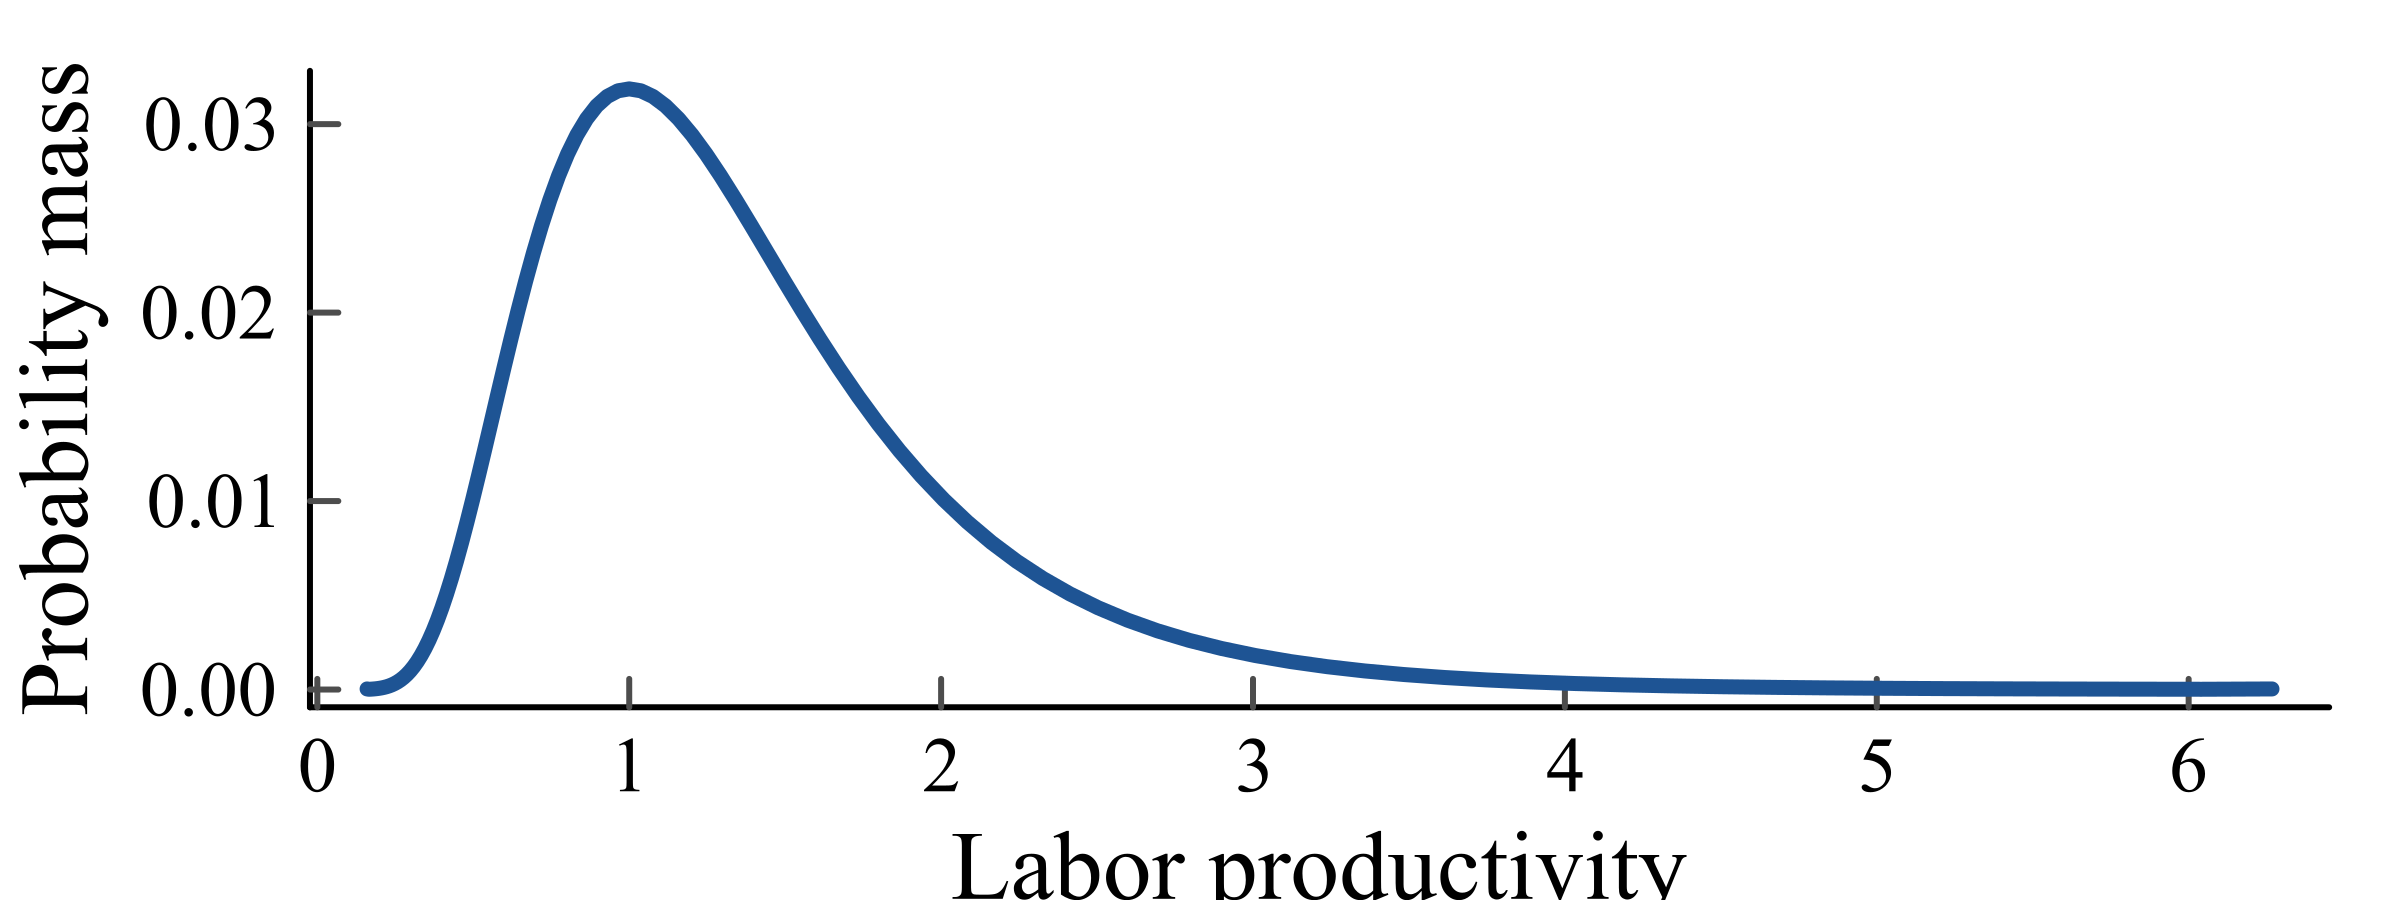

In [3]:
using Plots

blue = RGB(0.12, 0.33, 0.58)

plot(z, χ[:];
    xlabel="Labor productivity",
    ylabel="Probability mass",
    title="",
    lw=2.5,
    lc=blue,
    legend=false,
    dpi=600,
    size=(400, 150),

    # Fonts
    fontfamily="Times New Roman",
    guidefontsize=10,
    tickfontsize=8,

    # Appearance
    background_color=:white,
    foreground_color_axis=:gray30,
    grid=false,
    framestyle=:axes
)

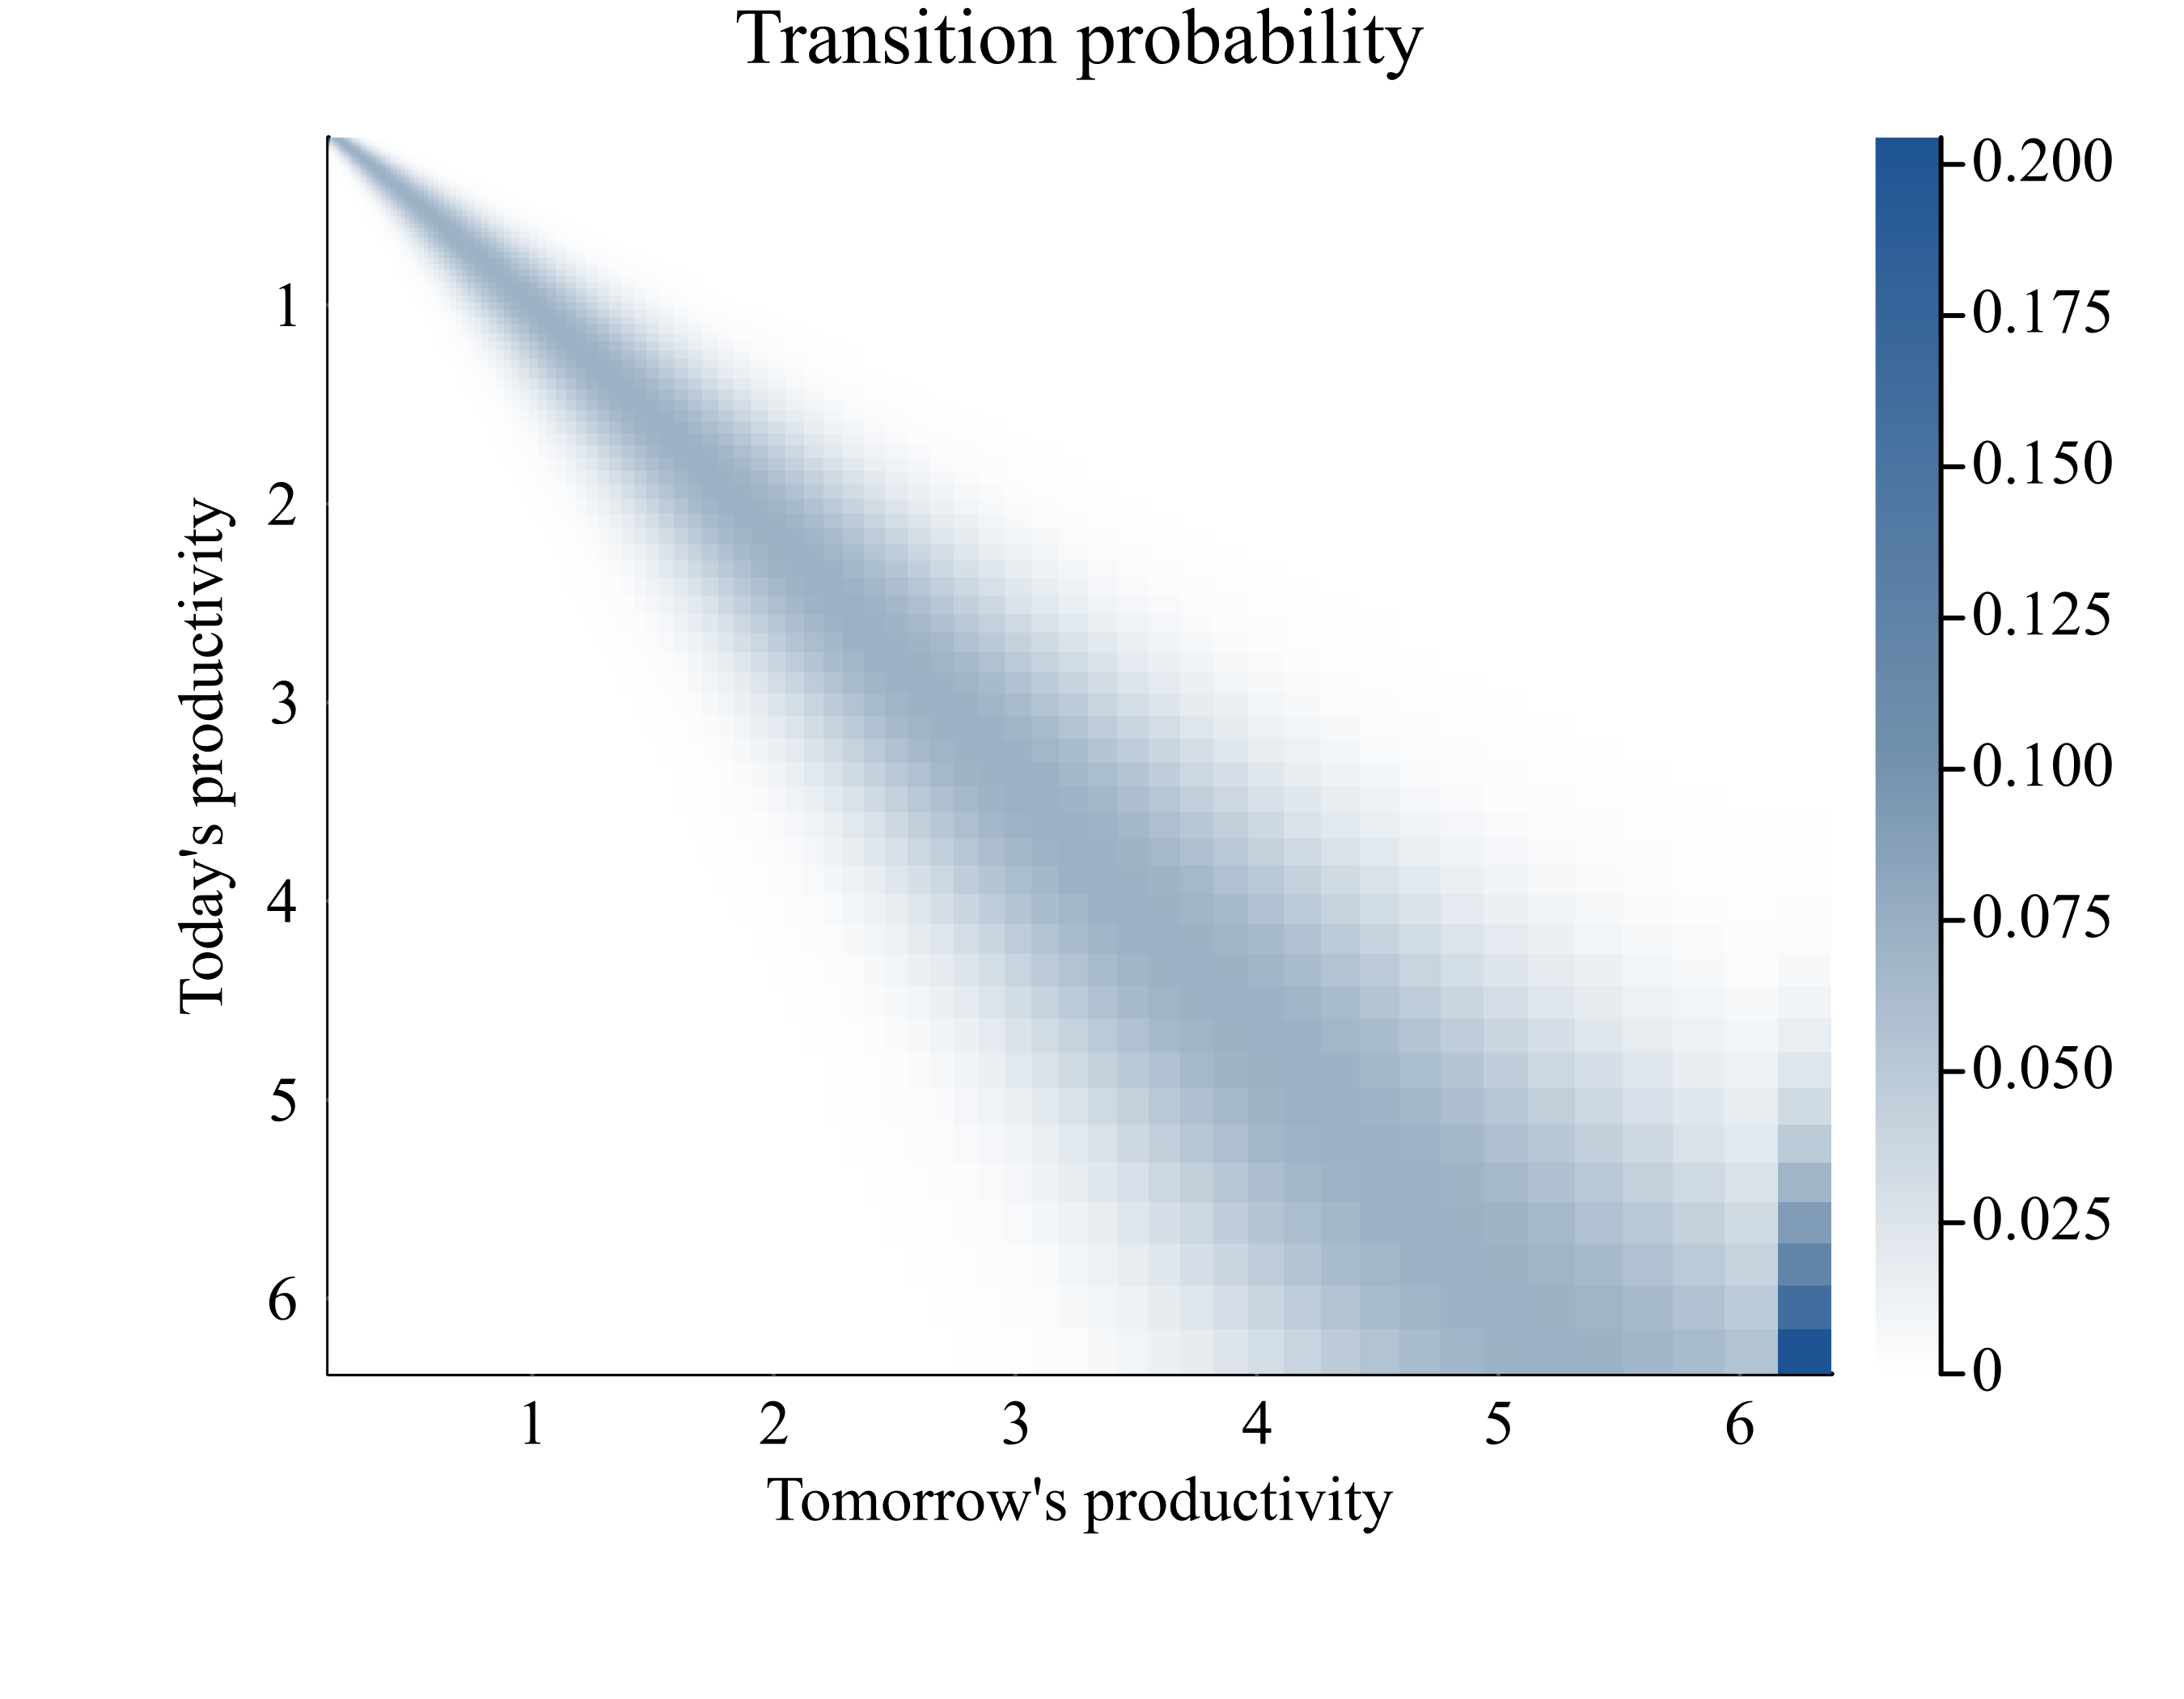

In [4]:
using Plots

blue = RGB(0.12, 0.33, 0.58)
blue_gray = RGB(0.45, 0.57, 0.68)
heat_colors = cgrad([:white, blue_gray, blue])

heatmap(z, z, P;
    xlabel="Tomorrow's productivity",
    ylabel="Today's productivity",
    title="Transition probability",
    titlefontsize=10,
    color=heat_colors,
    colorbar_title="",
    clims=(0, maximum(P)),
    yflip=true,
    dpi=600,
    size=(450, 350),

    # Margins
    bottom_margin=7Plots.mm,
    left_margin=8Plots.mm,
    right_margin=5Plots.mm,

    # Fonts
    fontfamily="Times New Roman",
    guidefontsize=8,
    tickfontsize=8,
    colorbar_titlefontsize=6,
    colorbar_tickfontsize=6,

    # Appearance
    background_color=:white,
    foreground_color_axis=:gray30,
    grid=false,
    framestyle=:axes
)

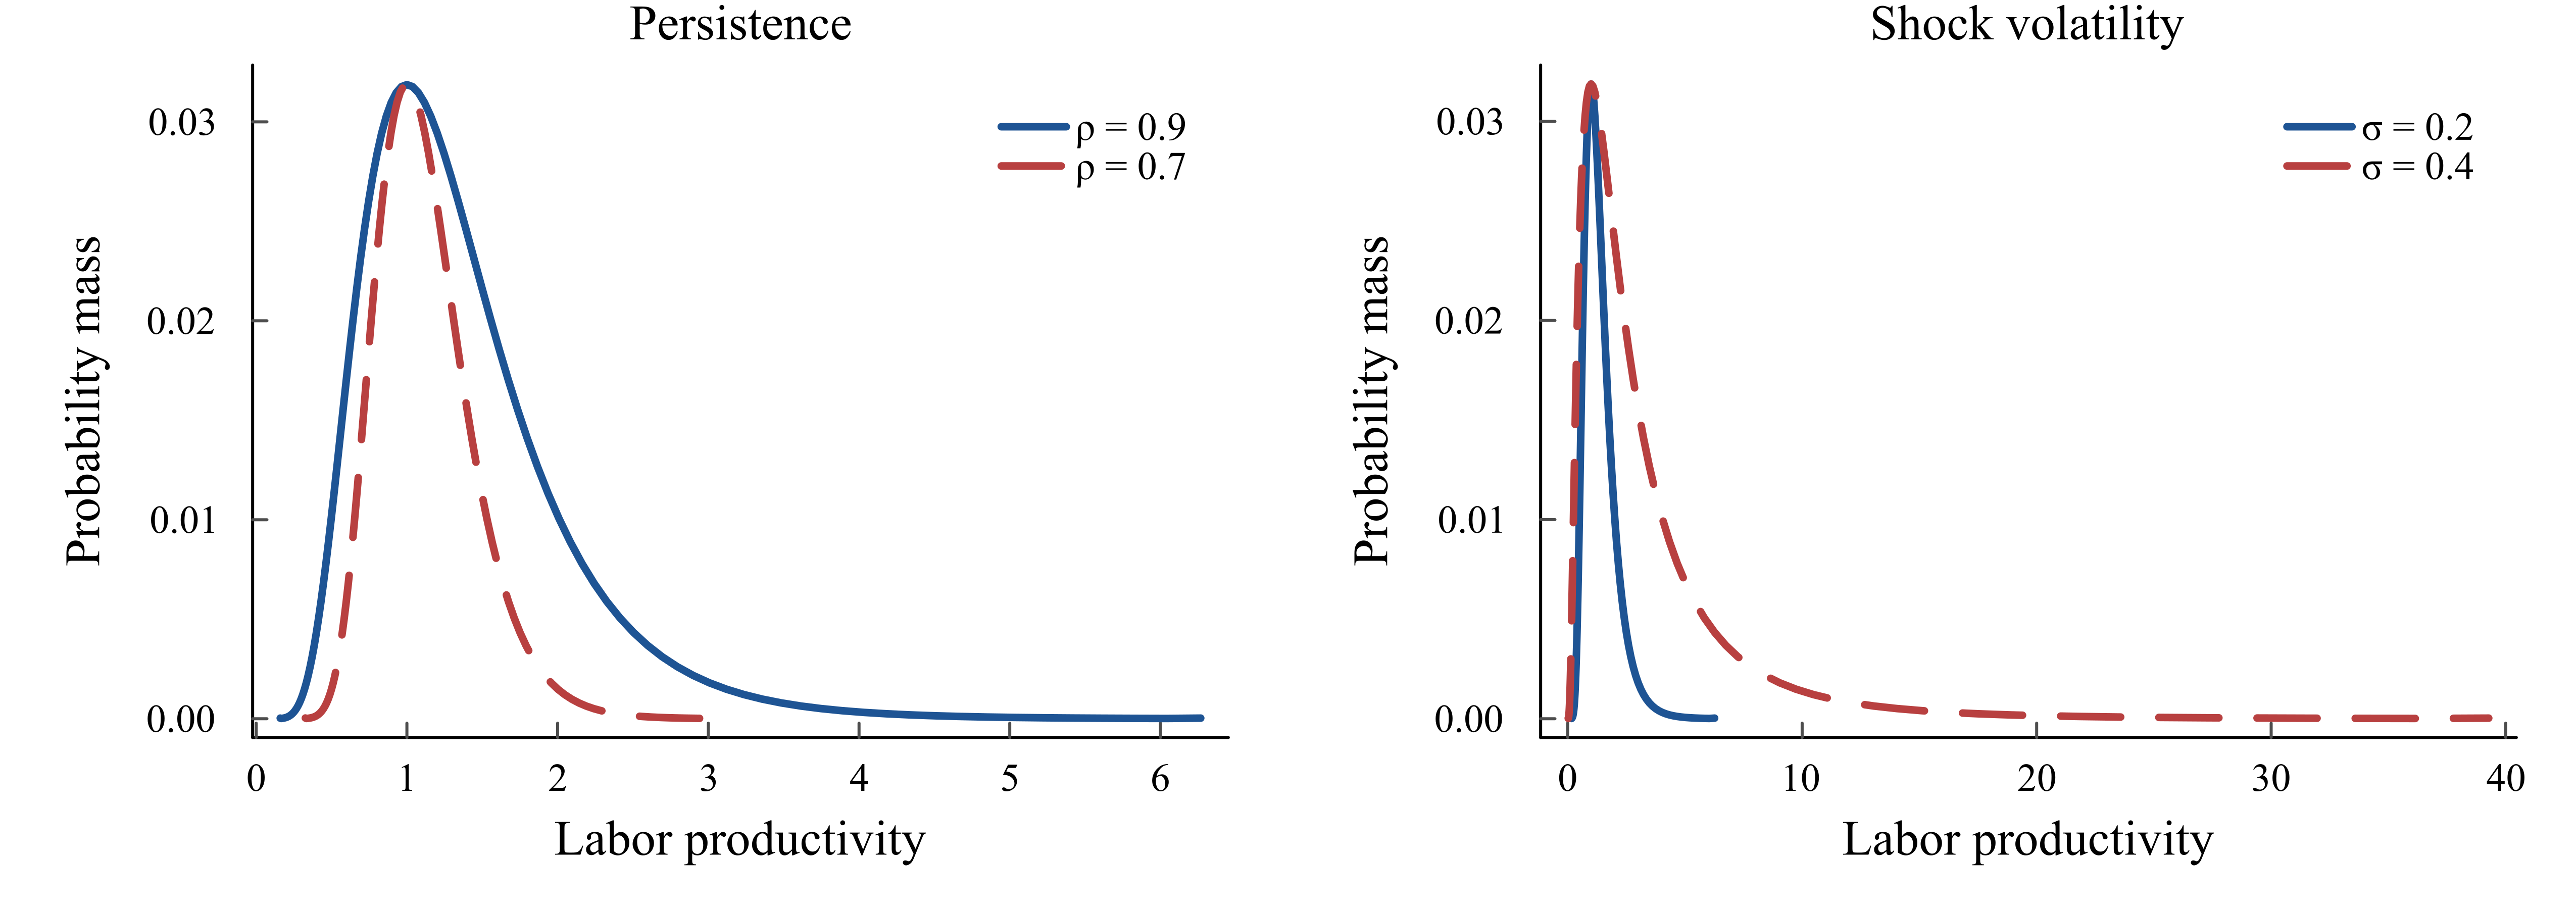

In [5]:
# comparison
using Plots

ω = 4.0; n = 101

# Colors
blue = RGB(0.12, 0.33, 0.58)
red  = RGB(0.72, 0.25, 0.25)

# Compute invariant distributions
z_base, P_base, χ_base = tauchen(0.9, 0.2, n, ω)
z_rho,  P_rho,  χ_rho  = tauchen(0.7, 0.2, n, ω)
z_sig,  P_sig,  χ_sig  = tauchen(0.9, 0.4, n, ω)

# Common styling
style = (
    xlabel="Labor productivity",
    ylabel="Probability mass",
    lw=2.5,
    fontfamily="Times New Roman",
    guidefontsize=10,
    tickfontsize=8,
    legendfontsize=8,
    titlefontsize=10,
    background_color=:white,
    foreground_color_axis=:gray30,
    grid=false,
    framestyle=:axes,
    legend=:topright,
    legend_background_color=:transparent,
    legend_foreground_color=:transparent
)

# Left: change persistence, holding σ = 0.2
p1 = plot(z_base, vec(χ_base);
    style...,
    title="Persistence",
    lc=blue,
    label="ρ = 0.9"
)
plot!(p1, z_rho, vec(χ_rho);
    lw=2.5,
    lc=red,
    ls=:dash,
    label="ρ = 0.7"
)

# Right: change shock volatility, holding ρ = 0.9
p2 = plot(z_base, vec(χ_base);
    style...,
    title="Shock volatility",
    lc=blue,
    label="σ = 0.2"
)
plot!(p2, z_sig, vec(χ_sig);
    lw=2.5,
    lc=red,
    ls=:dash,
    label="σ = 0.4"
)

# Combine panels
plot(p1, p2;
    layout=(1, 2),
    size=(850, 300),
    bottom_margin=7Plots.mm,
    left_margin=8Plots.mm,
    right_margin=3Plots.mm,
    dpi=600
)

### Algorithm
**Equilibrium Objects**:  
$V, \; g(a,z), \; \textcolor{red}{m(a,z)}, \; \textcolor{red}{K}, \; \textcolor{red}{r}, \; w$

1. Guess $r$.  
   ($L$ is determined by the stationary distribution of effective labor, and then $w$ is determined without knowing the value of $K$.)  

2. Given $w$ and $r$, perform the household's optimization and obtain the policy function $a' = g(a,z)$.  

3. Based on $a' = g(a,z)$ and the stationary distribution over $z$, $\chi(z)$, compute $m(a,z)$, the stationary distribution over $(a,z)$ space.  

4. Given $a' = g(a,z)$ and $m(a,z)$, compute the implied aggregate saving, and compare it with capital demand.  

5. If they are close enough, stop the procedure. If not, update the guess of $r$, return to step 1, and repeat the procedure until convergence.  


### What's different from similar models without idiosyncratic risk
- Need to capture the income process (in a discretized manner)  

- Need to take expectation (household problem)  

- Need to compute household distribution that is consistent with such income process, in solving equilibrium  

---

In [6]:
struct ModelParam{F<:Float64,I<:Int}
    α::F # capital share
    δ::F # capital depreciation
    A::F # TFP
    β::F # time discount factor
    μ::F # curvature
    ρ::F # persistence of income shock
    σ::F # volatility
    ω::F # support of income
    b::F # borrowing constraint
    maxa::F # maximum asset
    nz::I # # of income grid 
    na::I # # of asset grid
    a::Vector{F} # asset grid
end

In [7]:
function solve_household(w,r,p)

    # retrieve parameters
    β=p.β
    μ=p.μ
    ρ=p.ρ
    σ=p.σ
    ω=p.ω
    maxa=p.maxa
    nz=p.nz
    na=p.na
    b=p.b
    a=p.a

    # discretize income space and compute transition matrix
    z,P,χ = tauchen(ρ,σ,nz,ω)

    # value function and policy function
    v = zeros(na,nz)
    v_new = copy(v)
    # g = zeros(na,nz)
    g = fill(b,na,nz)
    g_arg = ones(Int,na,nz)

    # define utility function
    u(c) = μ == 1 ? log(c) : c^(1-μ)/(1-μ)

    # household problem
    penalty = -1.e+10
    v_temp = zeros(na)

    d=1.0
    ε=1.e-5
    iter=1
    maxiter=1000

    while (d>ε && iter<maxiter)
        for zc in eachindex(z)
        for ac in eachindex(a)
            v0=penalty
            v_temp.=penalty
            for acc in eachindex(a)
                c = (1+r)*a[ac]-a[acc]+w*z[zc]
                if (c>0)
                    val=u(c)
                    for zcc in eachindex(z) # take expectation
                        val += β*P[zc,zcc]*v[acc,zcc]
                    end
                else
                    val = penalty
                end

                v_temp[acc]=val

                if (val>v0)
                    v0=val
                else
                    break
                end
            end
            acc_arg = argmax(v_temp)
            v_new[ac,zc]=v_temp[acc_arg]
            g_arg[ac,zc]=acc_arg
            g[ac,zc]=a[acc_arg]
        end
        end
        d = maximum(abs.(v_new.-v))
        v .= (v .+ v_new)./2.0 
        iter+=1

        if (iter>maxiter)
            println("iter>maxiter")
            break
        end
        
    end

    if !isfinite(d) || d > ε
        error("Iteration failed to converge: residual = $d")
    end

    return g, g_arg

end

solve_household (generic function with 1 method)

In [35]:
using Printf

function solve_GE_Aiyagari(r,p)

    # retrieve parameters
    α=p.α
    δ=p.δ
    A=p.A
    ρ=p.ρ
    σ=p.σ
    ω=p.ω
    maxa=p.maxa
    nz=p.nz
    na=p.na
    a=p.a

    # discretize income space and compute transition matrix
    z,P,χ = tauchen(ρ,σ,nz,ω)
    # N = sum(z.*χ) # aggregate labor supply in efficiency unit
    N = sum(z .* vec(χ)) # since χ is a row matrix, use vec().
    K = 0.0
    w = 0.0

    # distribution
    m  = zeros(na,nz)
    ma = zeros(na) # asset distribution
    m0 = ones(na,nz)./(na*nz) # old distribution (initial guess)
    m1 = zeros(na,nz) # new distribution

    dif=1.0
    tol=1.e-4
    it=1
    maxit=50


    while (dif>tol && it<maxit)

        w = A*(1-α)*(A*α/(r+δ))^(α/(1-α))
        g, g_arg = solve_household(w,r,p)

        d=1.0
        ε=1.e-5
        iter=1
        maxiter=1000

        while (d>ε && iter<maxiter)

            for ac in eachindex(a)
            for zc in eachindex(z)
                acc = g_arg[ac,zc]
                for zcc in eachindex(z)
                    m1[acc,zcc]+=P[zc,zcc]*m0[ac,zc]
                end
            end
            end
            d = maximum(abs.(m1.-m0))
            m0 .= m1
            m0 .= m0 ./ sum(m0) # normalization for safety
            m1 .= 0.0
            iter+=1

            if (iter>maxiter)
                println("iter>maxiter for dist.")
                break
            end
        end

        # println("DISTRIBUTION COMPUTED")

        m .= m0
        K = sum(g.*m)
        imp_r = A*α*(K/N)^(α-1)-δ

        dif = abs(r-imp_r)

        # @printf("iter=%d, dif=%.5f\n", it, dif)
        it+=1

        # update
        adj = 0.9
        r = adj*r + (1.0-adj)*imp_r
        w = A*(1-α)*(A*α/(r+δ))^(α/(1-α))

    end

    if !isfinite(dif) || dif > tol
        error("General equilibrium did not converge: residual = $dif")
    end

    # compute asset distribution
    for ac in eachindex(a)
        ma[ac] = sum(m[ac,:])
    end

    return K,N,r,w,m,ma    

end

solve_GE_Aiyagari (generic function with 1 method)

In [48]:
α = 0.33; δ = 0.08; A = 1.0;
β = 0.95; μ = 2.0;
ρ = 0.6; σ = 0.4; ω = 4.0; nz = 5;
b=0.0; maxa=50.0; na = 151;

# discretize asset space
curv = 2.0
a = b .+ ((0:na-1) ./ (na-1)).^curv .* (maxa - b)

r0=0.02
p = ModelParam(α,δ,A,β,μ,ρ,σ,ω,b,maxa,nz,na,a);

K,N,r,w,m,ma = solve_GE_Aiyagari(r0,p);

g,g_arg = solve_household(w,r,p);

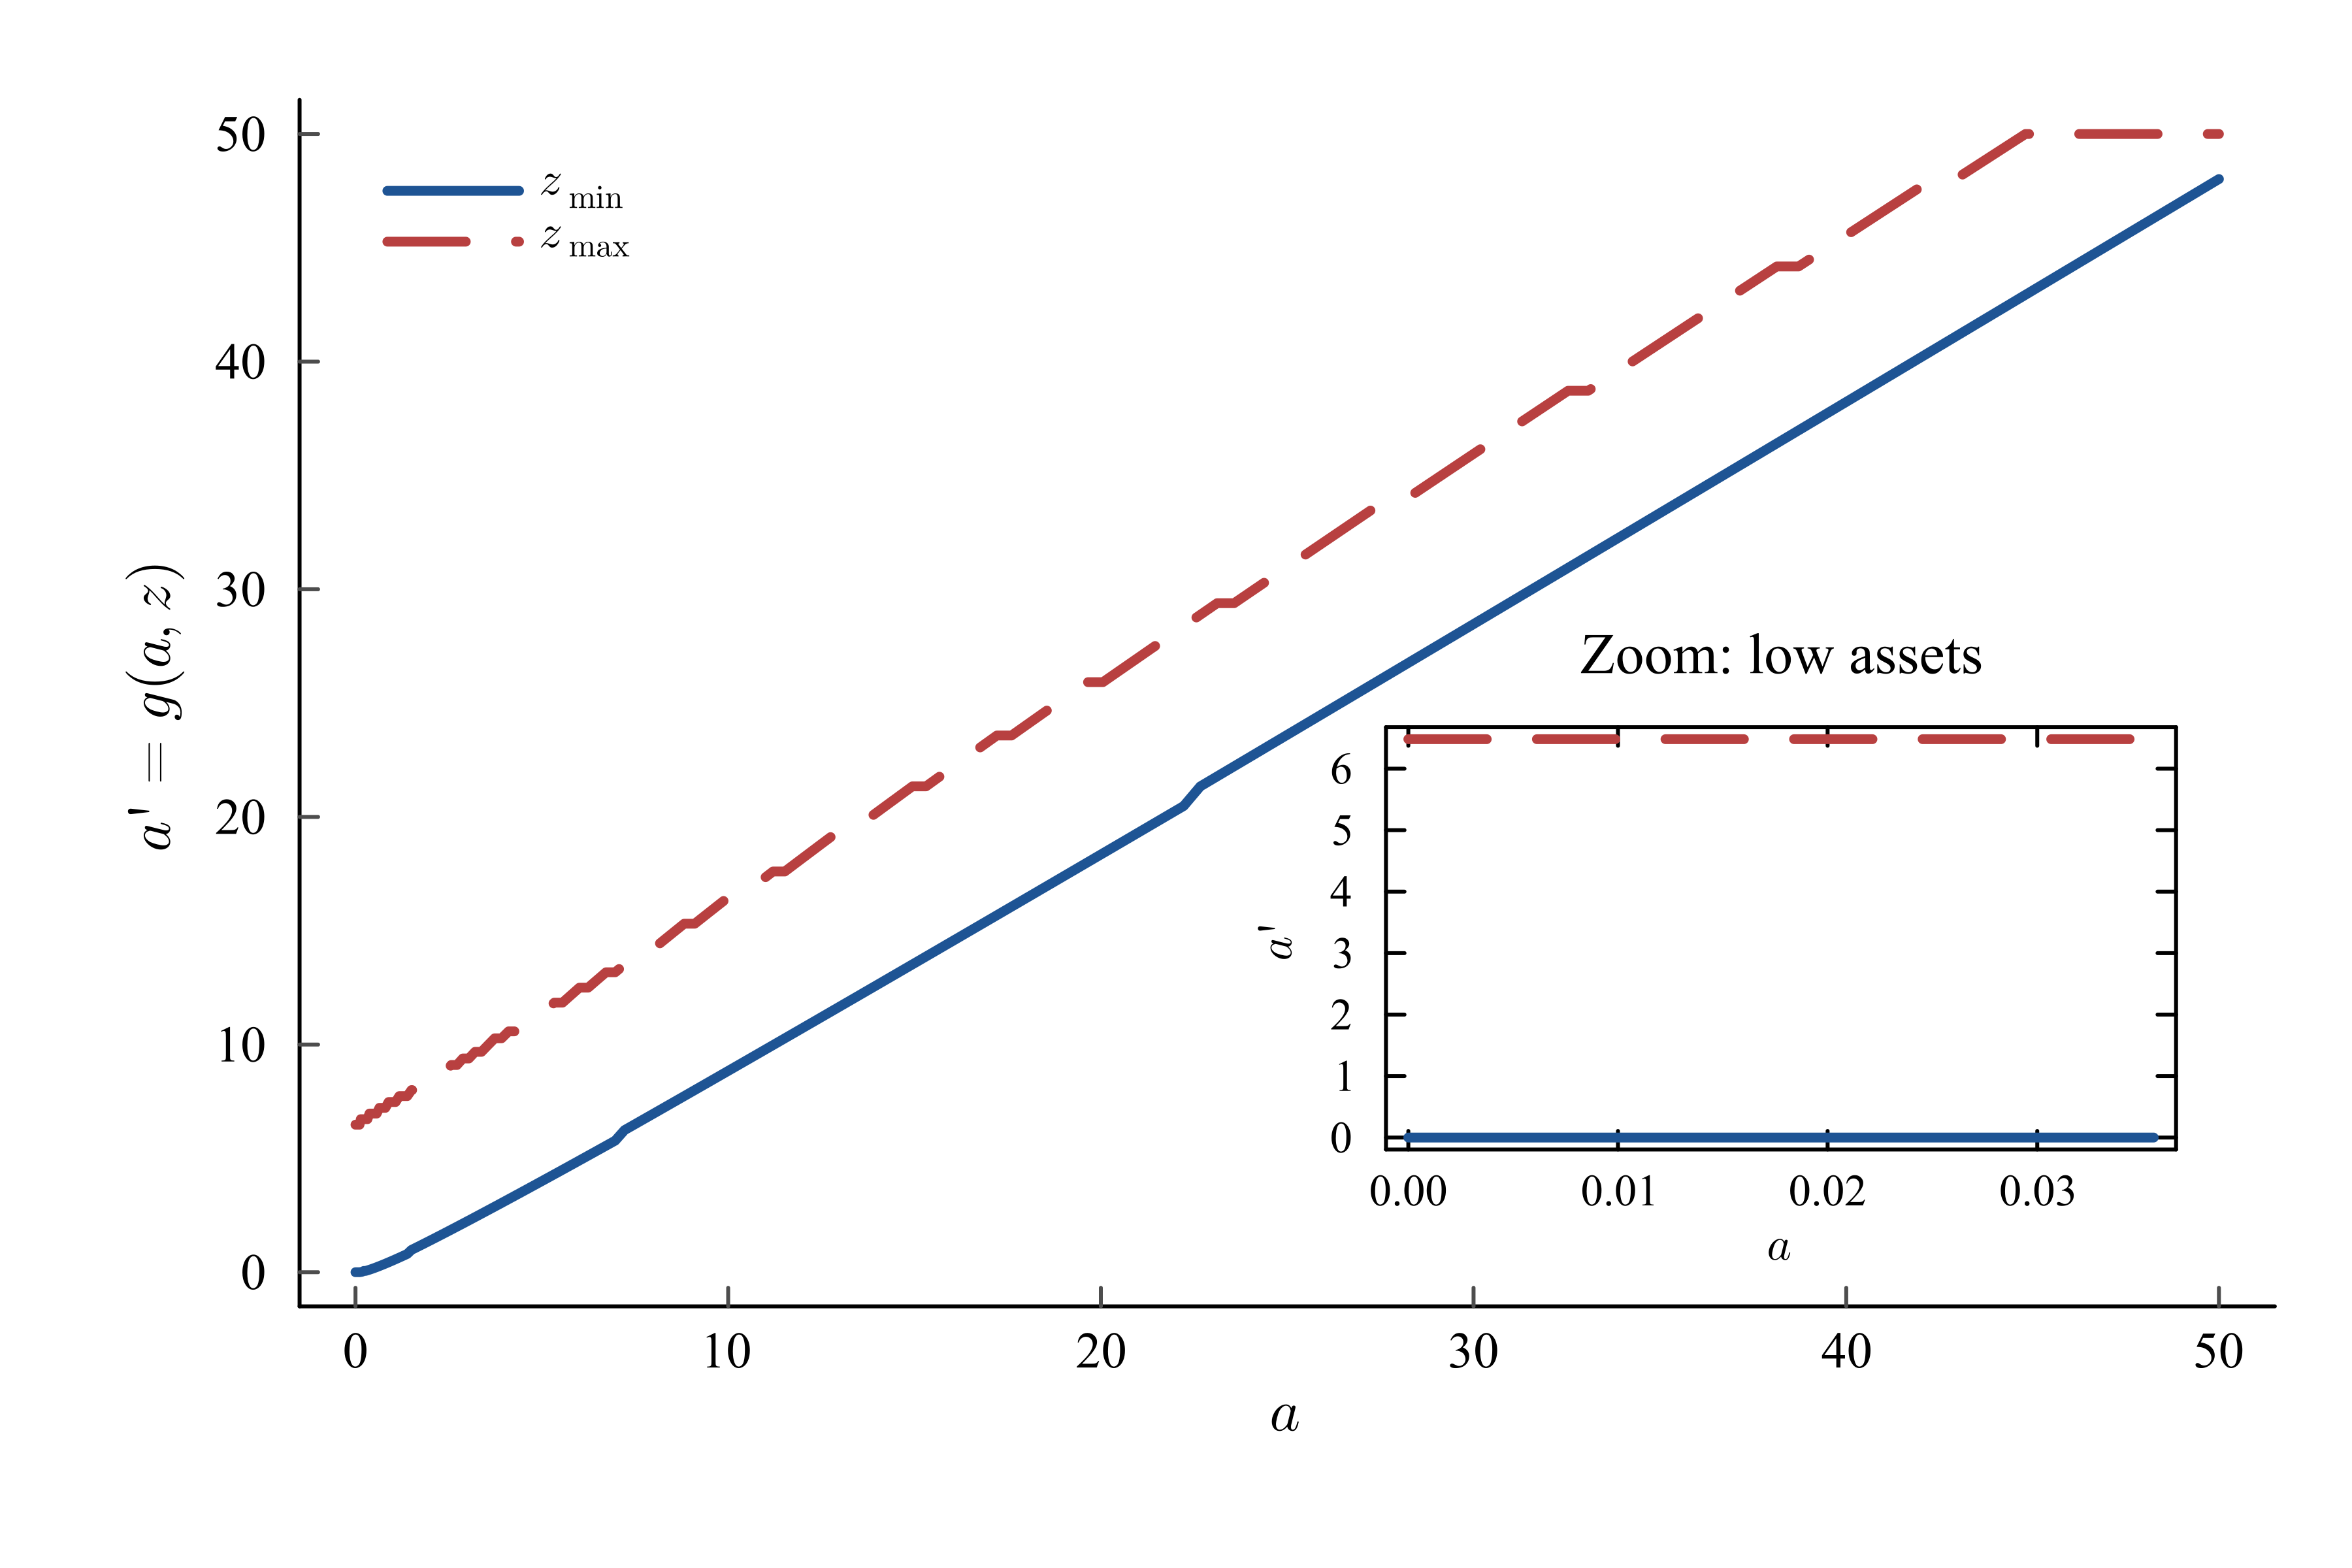

In [49]:
using Plots
using LaTeXStrings

blue = RGB(0.12, 0.33, 0.58)
red  = RGB(0.72, 0.25, 0.25)

# Main plot: both productivity states, full asset grid
p = plot(a, g[:, 1];
    xlabel=L"a",
    ylabel=L"a' = g(a,z)",
    lw=2.5,
    lc=blue,
    label=L"z_{\min}",
    dpi=600,
    size=(600, 400),

    fontfamily="Times New Roman",
    guidefontsize=10,
    tickfontsize=8,
    legendfontsize=8,

    background_color=:white,
    foreground_color_axis=:gray30,
    grid=false,
    framestyle=:axes,

    bottom_margin=7Plots.mm,
    left_margin=8Plots.mm,
    right_margin=3Plots.mm,

    legend=:topleft,
    legend_background_color=:transparent,
    legend_foreground_color=:transparent
)

plot!(p, a, g[:, end];
    subplot=1,
    lw=2.5,
    lc=red,
    ls=:dash,
    label=L"z_{\max}"
)

# Inset: the same two policy functions at low asset levels
idx = 1:5

plot!(p, a[idx], g[idx, 1];
    inset=(1, bbox(0.55, 0.52, 0.40, 0.35)),
    subplot=2,
    lw=2.5,
    lc=blue,
    label=false,

    title="Zoom: low assets",
    titlefontsize=9,
    xlabel=L"a",
    ylabel=L"a'",
    guidefontsize=8,
    tickfontsize=7,
    fontfamily="Times New Roman",

    xlims=:auto,
    ylims=:auto,
    legend=false,
    grid=false,
    framestyle=:box,
    background_color_inside=:white
)

plot!(p, a[idx], g[idx, end];
    subplot=2,
    lw=2.5,
    lc=red,
    ls=:dash,
    label=false
)

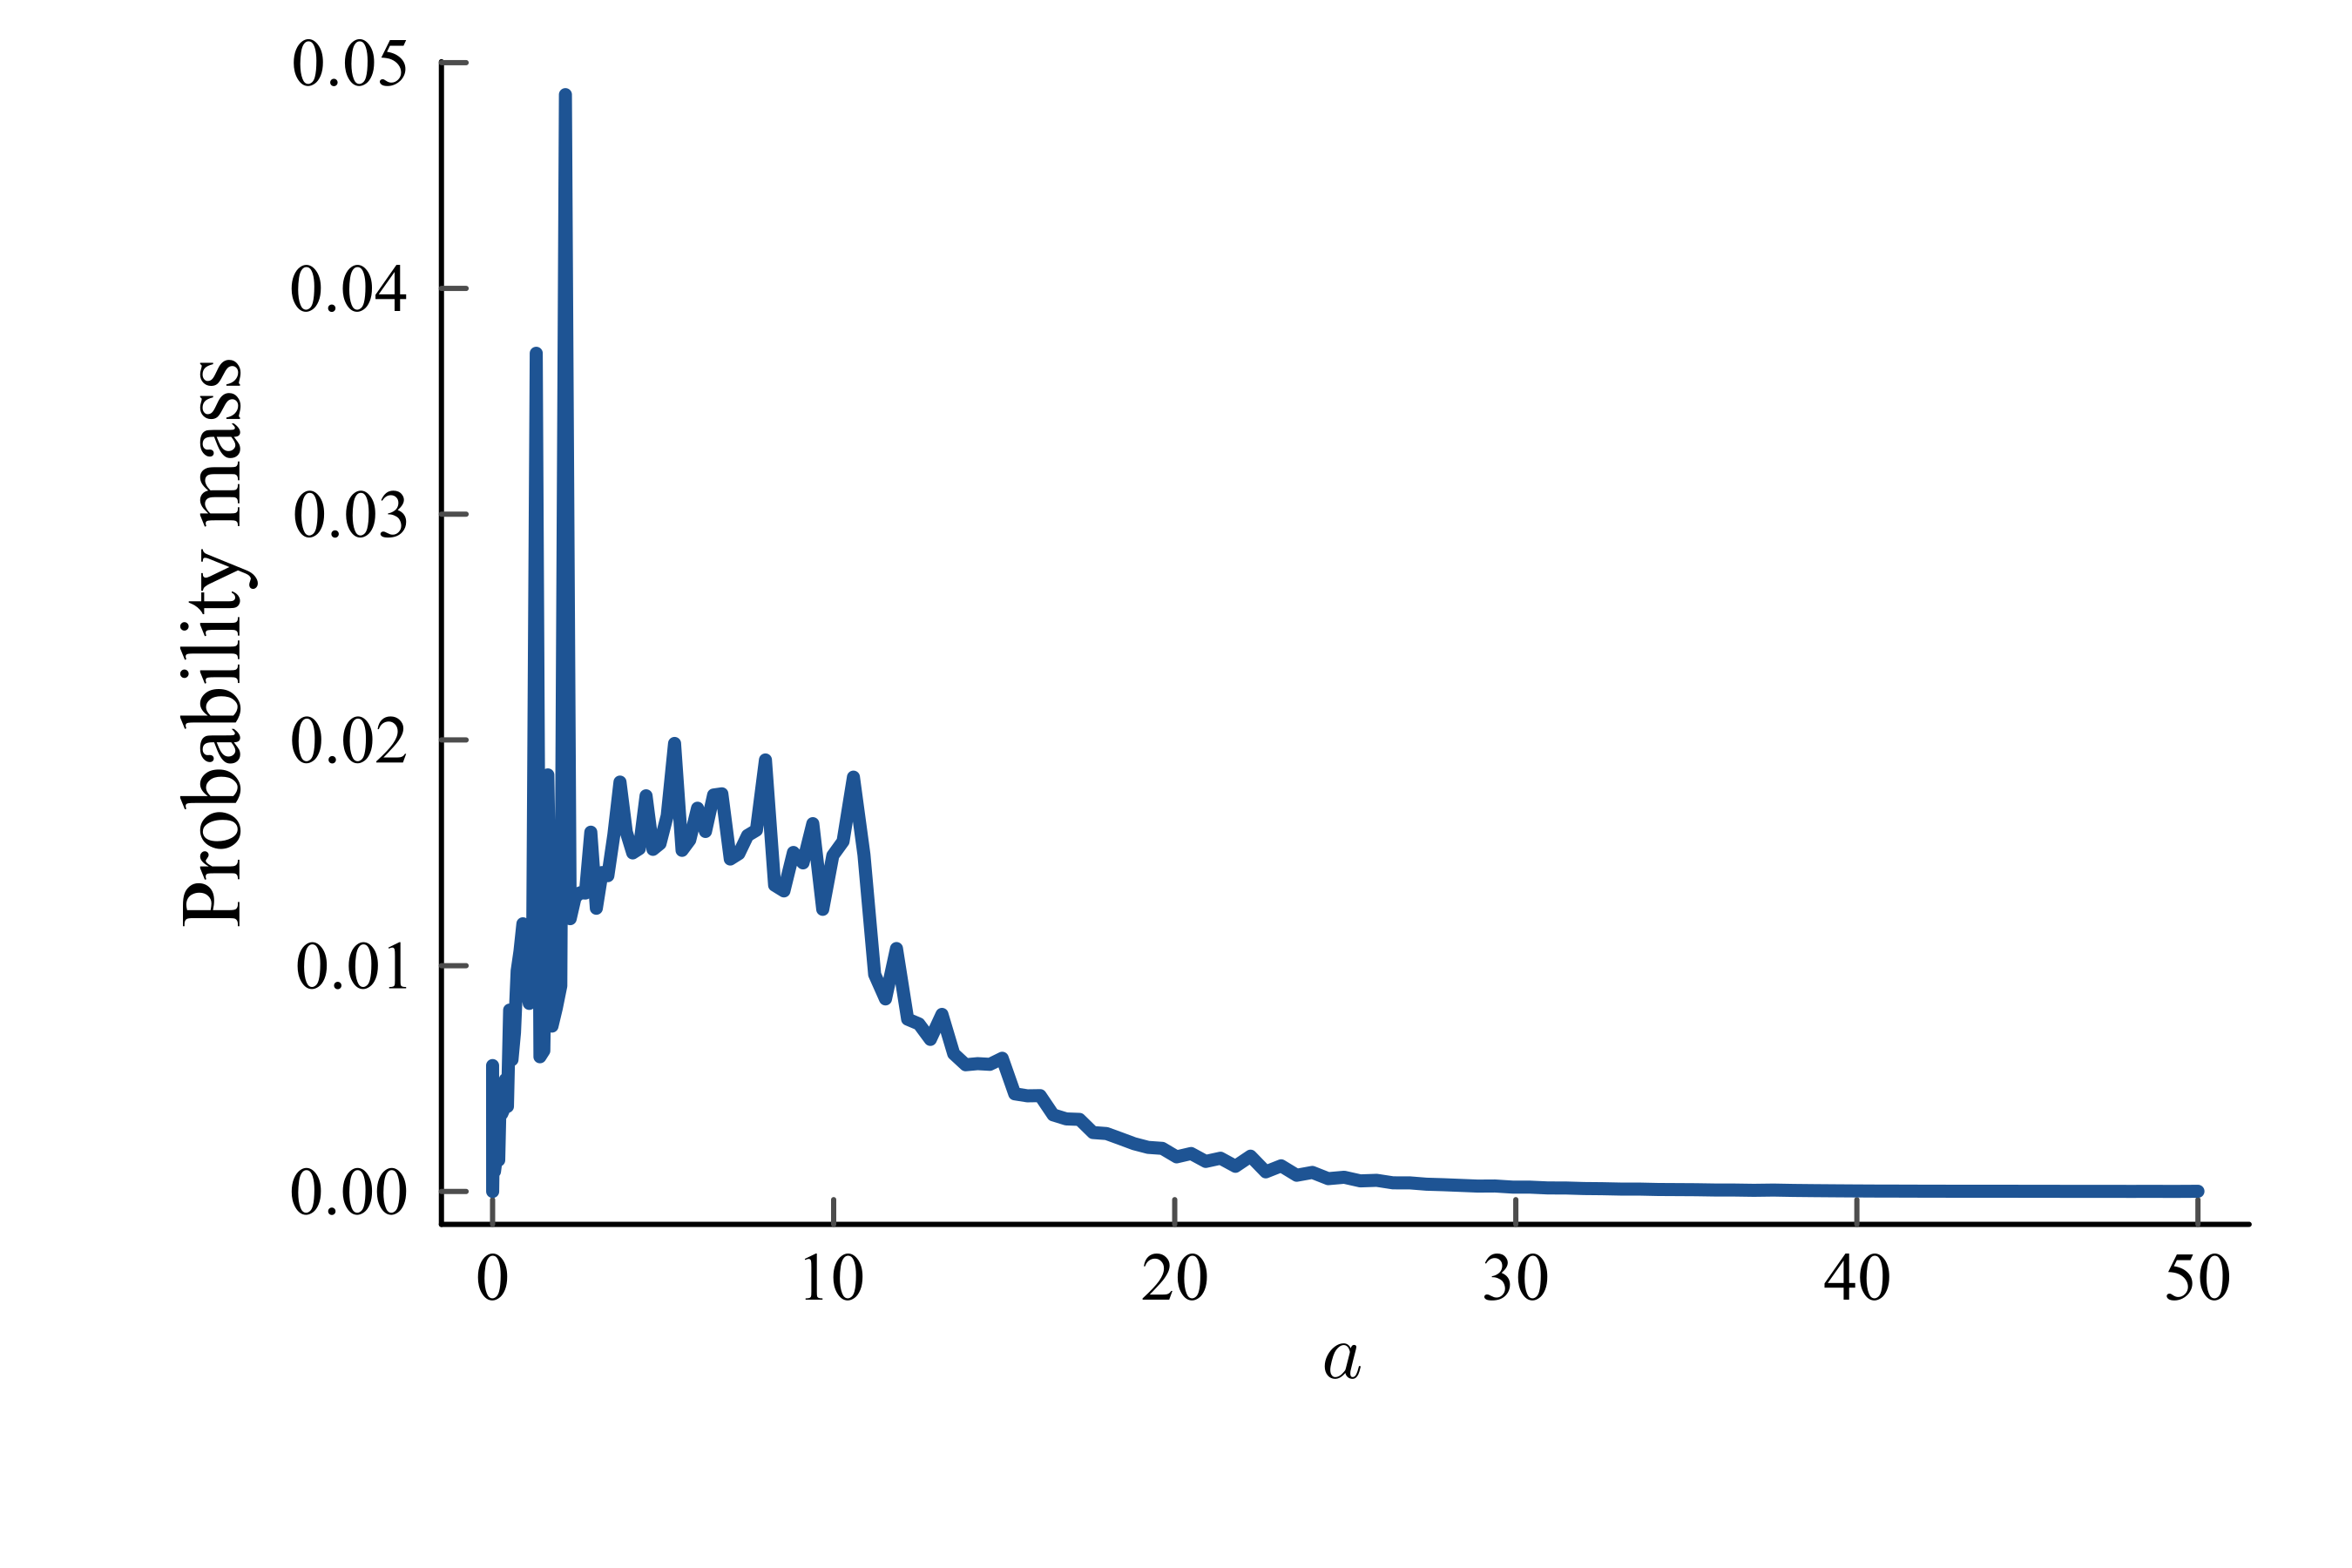

In [50]:
# asset distribution 
using Plots
using LaTeXStrings

blue = RGB(0.12, 0.33, 0.58)

plot(a, ma;
    xlabel=L"a",
    ylabel="Probability mass",
    title="",
    lw=2.5,
    lc=blue,
    legend=false,
    dpi=600,
    size=(450, 300),

    # Fonts
    fontfamily="Times New Roman",
    guidefontsize=10,
    tickfontsize=8,

    # Appearance
    background_color=:white,
    foreground_color_axis=:gray30,
    grid=false,
    framestyle=:axes,

    # Margins
    bottom_margin=7Plots.mm,
    left_margin=8Plots.mm,
    right_margin=3Plots.mm
)

### Comparison with the Complete Market Setting

**Complete Market Setting**

- $U'(c) = \beta (1+r)U'(c')$  
- $r = \frac{1}{\beta} - 1 \equiv \lambda$

**Aiyagari Model (Incomplete Market)**

- $U'(c)\;\ge\; \mathbb{E}[U'(c')](1+r)\beta$  
- Upward-sloping capital supply curve in $(r,k)$ space  
- $r < \lambda$: the equilibrium interest rate is less than in the complete market (intuition?)  

---

# Exercises on Aiyagari model: roles of taxation and redistribution

This exercise is primarily based on [lecture notes by Prof. Toshihiko Mukoyama (Georgetown University)](https://toshimukoyama.github.io/MyWebsite/Lecture2_Tokyo.pdf). All errors herein are mine.


Consider a government who imposes wealth tax $\tau$ (ie., take away $\tau a$) from households and transfer back in lump-sum manner.

0. (Optional, if time permits) Refactor the code by separating it into: (i) a function for solving the household problem with interest rate as input, (ii) a routine for solving general equilibrium, and (iii) a struct for model parameters. Place each component in its own Julia source file (e.g., `household.jl`, `equilibrium.jl`, `params.jl`).  

1. Introduce such government into the model, considering government budget balance. Set $\tau=0.05$. Equilibrium lump-sum transfer, $T$, is determined endogenously.  

  - We need to change the function `solve_household` by including $\tau$ and $T$ as additional inputs and by adding them to the budget constraint.

  - We also need to change the function `solve_stationary` by including $\tau$ and $T$ as additional inputs, and by adding an update for $T$ to check whether the government budget constraint $\tau K = T$ is satisfied.  


2. Evaluate the welfare effects of the policy based on the ex-ante perspective. That is, compute the consumption equivalence according to the formula:

$$
\mathbb{E}\sum_{t=0}^\infty u(c^0_t(a_t,z_t)(1+\lambda)) = \mathbb{E}\sum_{t=0}^\infty u(c^1_t(a_t,z_t)),
$$
where functions with super script 0 and 1 denote the equilibrium policy functions without and with the wealth tax. The right-hand side can be easily computed based on the equilibrium value function and the stationary distribution $m$.

- In computing the CEV, you may construct additional functions: (1) `imp_value`, which returns the expected lifetime utility given baseline policy functions, the value function, and the distribution, with input $\lambda$; and (2) `compute_CEV`, which computes CEV using `imp_value`.

2.1. Does the policy improve (ex-ante) welfare? If so, why? You may decompose the welfare change into the change in the distribution and the change in the value function, given that the right-hand side is defined as $\sum_{x} V(x)\, m(x)$, where $x$ is the state vector.

2.2. Do the welfare implications of the redistribution policy differ if income is less volatile (e.g., smaller $\sigma$)?  

2.3. (Optional) Solve the transitional dynamics.